In [1]:
from pathlib import Path
import sys

# Resolve paths and imports from either the project root or notebooks directory.
PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid

%matplotlib inline

In [2]:
DATA_FULL = PROJECT_ROOT / "data" / "stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
p_bat_init = y[0]
y = y[1:]
x = np.diff(df.loc[df["segment_id"] == 1]["time_s"])

# Static storage sizing
Over 42 power profile trials, requirements described by:
$$E_{req} = \int P(t)\ \mathrm{d}t$$
$$P_{req} = \max P(t)$$

In [3]:
df["energy_kWh"] = (
    df.groupby("segment_id")["node_gpu_power_W"]
    .transform(
        lambda x: cumulative_trapezoid(
            x,
            df.loc[x.index, "time_s"],
            initial=0
        ) / 3_600_000
    )
)

bat_only = df.groupby("segment_id").agg(
    P_req=("node_gpu_power_W", "max"),
    E_req=("energy_kWh", "last")
)

# Convert kWh to Wh
bat_only["E_req"] *= 1000

Requirements met by following systems:
$$N_{b} P_{b} \geq P_{req},$$
$$N_{b} E_{b} \geq E_{req}$$

We have to approximate power per battery cell:
$$P_b = I^\text{discharge}_\text{max} (U_\text{nominal} - I^\text{discharge}_\text{max} R_\text{int}) $$

We can calculate the nominal energy capacity and the power-limited energy over the trial:
$$E_b = \min(E_b^\text{nom}, E_b^\text{pow})$$

$$E_b^\text{nom} = U_\text{nominal} \cdot Q_\text{nominal}$$
$$E_b^\text{pow} = P_{b}t_{\text{trial}}$$

Thus, minimal amount of battery cells described by:
$$N_{b} = \max (\lceil\frac{E_{req}}{E_b}\rceil, \lceil\frac{P_{req}}{P_b}\rceil)$$

In [4]:
# SonyLFP properties
U_nom =3.2 # V

# discharge only trials -> max discharge rate!
Q_nom =3.0 # Ah
C_max_discharge = 6.6 # 1/h

I_max_discharge = Q_nom * C_max_discharge # approx 20 A

R_int = 50e-3 # Rint LUT mean @ 25°C

t_trial = 3 / 60 # h

P_b = I_max_discharge * (U_nom - I_max_discharge * R_int) # W

E_b_nom = U_nom * Q_nom # Wh
E_b_pow = P_b * t_trial # Wh

E_b = min(E_b_nom, E_b_pow) # Wh

In [5]:
bat_only["N_b_energy"] = np.ceil(bat_only["E_req"] / E_b).astype(int)
bat_only["N_b_power"] = np.ceil(bat_only["P_req"] / P_b).astype(int)

bat_only["N_b"] = bat_only[["N_b_energy", "N_b_power"]].max(axis=1)

# amount of cells power limited!
print(bat_only["N_b"].median(), bat_only["N_b"].max(), bat_only["N_b"].quantile(0.95))
bat_only.head()

123.0 174 164.95


,P_req,E_req,N_b_energy,N_b_power,N_b
segment_id,,,,,
1,4638.2142,123.309949,57,106,106
2,5297.7384,126.231137,58,122,122
3,5774.4390,124.146737,57,132,132
4,5754.6242,247.967713,114,132,132
5,4638.2142,123.309949,57,106,106


## Introducing supercaps

We can additionally formulate
$$N_{b} E_{b} + N_{sc} E_{sc} \geq E_{req},$$
$$N_{b} P_{b} + N_{sc} P_{sc} \geq P_{req}$$

and

$$N_b \geq \frac{E_{req}-N_{sc}E_{sc}}{E_b}$$
$$N_b \geq \frac{P_{req}-N_{sc}P_{sc}}{P_b}$$

and finally:
$$N_{b}(N_{sc}) = \max(\left\lceil \frac{E_{req}-N_{sc}\min(E_{sc}^\text{nom}, E_{sc}^\text{pow})}{\min(E_b^\text{nom}, E_b^\text{pow})} \right\rceil, \left\lceil \frac{P_{req}-N_{sc}P_{sc}}{P_b} \right\rceil)$$

with similar energy limitation:
$$E_{sc} = \min(E_{sc}^\text{usable}, E_{sc}^\text{pow})$$

$$E_{sc}^\text{usable} = \frac{C}{2*3600} (V_\text{rated}^2 -  V_\text{min}^2)$$
$$E_{sc}^\text{pow} = P_{sc}t_{\text{trial}}$$

In [6]:
# 1 sc example
N_sc = 1

p_peak = bat_only.copy().drop(columns=["N_b_energy", "N_b_power", "N_b"])

# skeleton properties
capacitance = 3200.0    # F
rated_voltage = 2.85    # V
min_voltage = 1.425     # V
t_trial = 3 / 60        # h

P_sc = 11.3e3 # peak power!

E_sc_usable = (
    (rated_voltage**2 - min_voltage**2)
    * capacitance / 2 / 3600
)

E_sc_pow = P_sc * t_trial

E_sc = min(E_sc_usable, E_sc_pow)

p_peak["N_b_energy"] = np.ceil((p_peak["E_req"] - N_sc * E_sc) / E_b).astype(int)
p_peak["N_b_power"] = np.ceil((p_peak["P_req"] - N_sc * P_sc) / P_b).astype(int)

p_peak["N_b"] = p_peak[["N_b_energy", "N_b_power"]].max(axis=1)

print(p_peak["N_b_energy"].median(), p_peak["N_b_energy"].max(), p_peak["N_b_energy"].quantile(0.95))
print(p_peak["N_b_power"].median(), p_peak["N_b_power"].max(), p_peak["N_b_power"].quantile(0.95))

p_peak.head()

84.5 133 128.0
-136.0 -85 -93.05000000000001


,P_req,E_req,N_b_energy,N_b_power,N_b
segment_id,,,,,
1,4638.2142,123.309949,56,-152,56
2,5297.7384,126.231137,57,-137,57
3,5774.4390,124.146737,56,-126,56
4,5754.6242,247.967713,113,-126,113
5,4638.2142,123.309949,56,-152,56


Approximation of one static value for $P_{sc}$ difficult (is it even sensible?). Using $P_{sc} = P_{\text{peak}}$, 1 sc cell would cover more than enough of the power requirements -> using peak power as $P_sc$ is unrealistic.

Instead of 

$$P_0 = P_\text{peak}$$


we can approximate $P_{sc}$ using several (more or less conservative) values:
$$P_1 = I^{\Delta 15 °\mathrm{C}}_\text{max}(V_\text{min} - I^{\Delta 15 °\mathrm{C}}_\text{max}R_\text{int})$$
$$P_2 = I^{\Delta 15 °\mathrm{C}}_\text{max}( V_\text{avg}- I^{\Delta 15 °\mathrm{C}}_\text{max}R_\text{int})$$
$$P_3 = I^{\Delta 15 °\mathrm{C}}_\text{max}( V_\text{rated}- I^{\Delta 15 °\mathrm{C}}_\text{max}R_\text{int})$$
$$P_4 = I^\text{peak}_\text{max}( V_\text{rated}- I^\text{peak}_\text{max}R_\text{int})$$



In [7]:
R_int = 0.18e-3

def calc_P_sc(
        I,
        V,
        R
):
    return I*(V-I*R)

def calc_N_b(
        N_sc,
        P_sc
):
    df = bat_only.copy().drop(columns=["N_b_energy", "N_b_power", "N_b"])
    df["N_b_energy"] = np.ceil((df["E_req"] - N_sc * E_sc) / E_b).astype(int)
    df["N_b_power"] = np.ceil((df["P_req"] - N_sc * P_sc) / P_b).astype(int)

    df["N_b"] = df[["N_b_energy", "N_b_power"]].max(axis=1)

    return df

In [8]:
N_sc = 1

# most conservative approximation with I ^= Max continuous current, ΔT = 15°C and V ^= V_min
P_sc1 = calc_P_sc(167, 1.425, R_int)
print(P_sc1)
c1 = calc_N_b(1, P_sc1)
print(c1["N_b"].median(), c1["N_b"].max(), c1["N_b"].quantile(0.95))
print(c1["N_b_power"].median(), c1["N_b_power"].max(), c1["N_b_power"].quantile(0.95), '\n')



# I ^= Max continuous current, ΔT = 15°C, V ^= avg(rated voltage, min_voltage)
P_sc2 = calc_P_sc(167, np.mean([1.425, 2.85]), R_int)
print(P_sc2)
c2 = calc_N_b(1, P_sc2)
print(c2["N_b"].median(), c2["N_b"].max(), c2["N_b"].quantile(0.95))
print(c2["N_b_power"].median(), c2["N_b_power"].max(), c2["N_b_power"].quantile(0.95), '\n')


# I ^= Max continuous current, ΔT = 15°C, V ^= rated voltage
P_sc3 = calc_P_sc(167, 2.85, R_int)
print(P_sc3)
c3 = calc_N_b(1, P_sc3)
print(c3["N_b"].median(), c3["N_b"].max(), c3["N_b"].quantile(0.95))
print(c3["N_b_power"].median(), c3["N_b_power"].max(), c3["N_b_power"].quantile(0.95), '\n')



# I ^= Maximum peak current for 1 second, V ^= rated voltage
P_sc4 = calc_P_sc(2890, 2.85, R_int)
print(P_sc4)
c4 = calc_N_b(1, P_sc4)
print(c4["N_b"].median(), c4["N_b"].max(), c4["N_b"].quantile(0.95))
print(c4["N_b_power"].median(), c4["N_b_power"].max(), c4["N_b_power"].quantile(0.95), '\n')

232.95498
117.0 168 159.0
117.0 168 159.0 

351.94248
115.0 166 156.95
115.0 166 156.95 

470.92998
112.0 163 153.95
112.0 163 153.95 

6733.122
84.5 133 128.0
-31.0 20 10.949999999999996 



In [9]:
medians = pd.DataFrame({
    "n_sc" : np.arange(0, 21),
    "N_b" : np.arange(0, 21),
    "N_b_energy" : np.arange(0, 21),
    "N_b_power" : np.arange(0, 21),
})

maxs = pd.DataFrame({
    "n_sc" : [],
    "N_b" : [],
    "N_b_energy" : [],
    "N_b_power" : []
})

p095s = pd.DataFrame({
    "n_sc" : [],
    "N_b" : [],
    "N_b_energy" : [],
    "N_b_power" : []
})


sc_range = np.arange(0, 31)
cols = ["N_b", "N_b_energy", "N_b_power"]

def calc_stats(P_sc):
    stats = (
        pd.concat(
            [
                calc_N_b(n_sc, P_sc).assign(n_sc=n_sc)
                for n_sc in sc_range
            ],
            ignore_index=True
        )
        .groupby("n_sc")[cols]
        .agg(["median", "max", lambda x: x.quantile(0.95)])
    )

    return stats.rename(columns={"<lambda_0>": "p095"})


# Calculate statistics for all four P_sc values
stats1 = calc_stats(P_sc1)
stats2 = calc_stats(P_sc2)
stats3 = calc_stats(P_sc3)
stats4 = calc_stats(P_sc4)

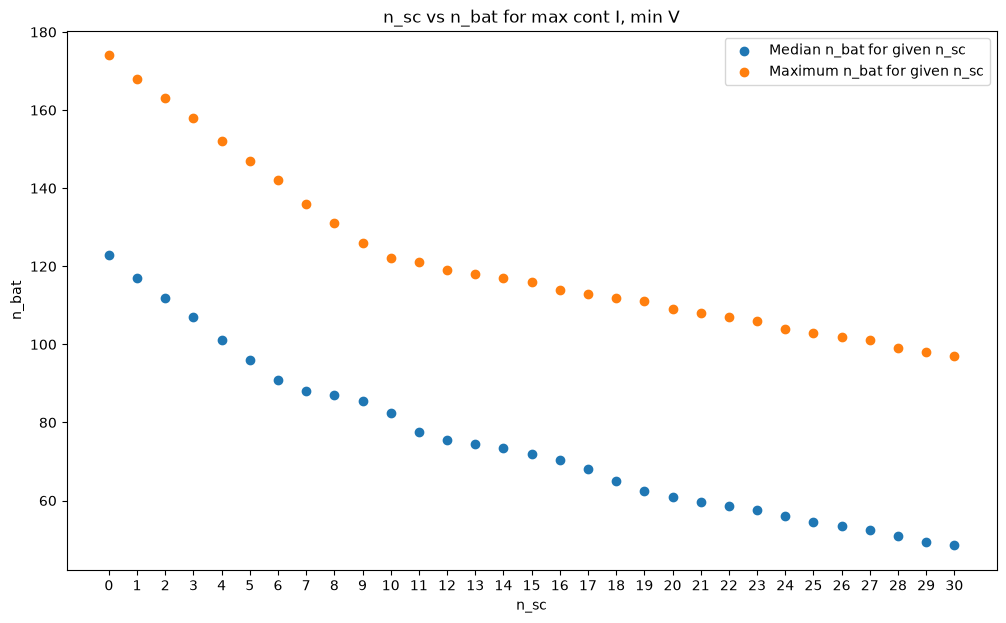

In [10]:
plt.figure(figsize=(12,7))

plt.scatter(
    stats1.index.to_list(),
    stats1["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats1.index.to_list(),
    stats1["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats1.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, min V")

plt.show()

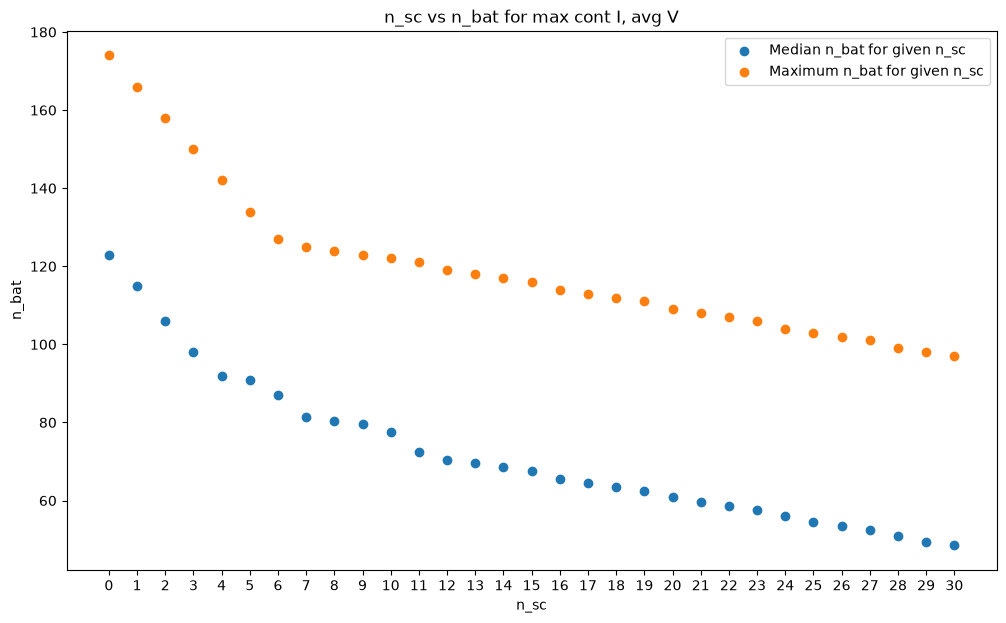

In [11]:
stats = stats2

plt.figure(figsize=(12,7))

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, avg V")

plt.show()

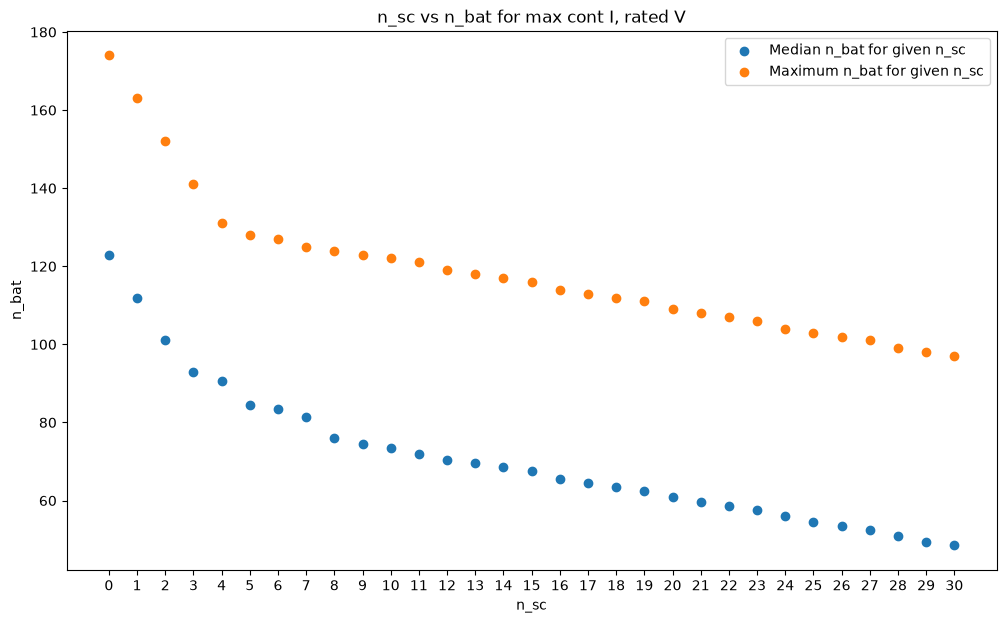

In [12]:
stats = stats3

plt.figure(figsize=(12,7))

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, rated V")

plt.show()

"Optimal" bat to sc ratio at the end of the higher slope parts -> best "bang for buck"

In [13]:
# "worst case" prediction, 10 sc, 122 bat
print(stats1["N_b"]["max"][10])

# "best case" prediction, 8 sc, 76 bat
print(stats3["N_b"]["median"][8])

122
76.0


## Trying it out in sim

In [14]:
taus = [0.001, 0.1, 1, 5, 10, 100, 250, 1000]

ps_worst = {
    "bat_series": 122,
    "bat_parallel": 1,
    "sc_series": 10,
    "sc_parallel": 1,
    "start_soc_bat" : 1,
    "start_soc_sc" : 1

}

ps_best = {
    "bat_series": 76,
    "bat_parallel": 1,
    "sc_series": 8,
    "sc_parallel": 1,
    "start_soc_bat" : 1,
    "start_soc_sc" : 1
}

conf_worst = [{**ps_worst, "tau": tau} for tau in taus]
conf_best = [{**ps_best, "tau": tau} for tau in taus]

In [15]:
from tqdm.auto import tqdm

from src.optimise import eval_configs

results = []
trials = df.groupby("segment_id")

for segment_id, trial in tqdm(trials, total=trials.ngroups):
    power = -trial["node_gpu_power_W"].to_numpy()
    time = trial["time_s"].to_numpy()
    x = np.diff(time)

    for case, configs in [
        ("worst_case", conf_worst),
        ("best_case", conf_best)
    ]:
        res = eval_configs(
            configs,
            x,
            power[1:],
            power[0],
            logging=True,
            max_workers=4
        )

        for run in res:
            log = run["log"]
            log["time_s"] = time[1:] - time[0]

            run["case"] = case
            run["segment_id"] = segment_id
            run["error_fraction"] = log["error_fraction"].iloc[-1]
            run["loss_fraction"] = log["loss_fraction"].iloc[-1]

        results.extend(res)

  0%|          | 0/42 [00:00<?, ?it/s]

In [16]:
res_trials = pd.DataFrame(results)
res_trials["success"] = res_trials["error_fraction"] <= 0.005

res_trials = res_trials.set_index(
    ["case", "segment_id", "tau"]
).sort_index()

res_trials.drop(columns="log")

bat_series  bat_parallel  sc_series  \
case       segment_id tau                                             
best_case  1          0.001             76             1          8   
                      0.100             76             1          8   
                      1.000             76             1          8   
                      5.000             76             1          8   
                      10.000            76             1          8   
...                                    ...           ...        ...   
worst_case 42         5.000            122             1         10   
                      10.000           122             1         10   
                      100.000          122             1         10   
                      250.000          122             1         10   
                      1000.000         122             1         10   

                                sc_parallel  start_soc_bat  start_soc_sc  \
case       segment_id tau                                                  
best_case  1          0.001               1              1             1   
                      0.100               1              1             1   
                      1.000               1              1             1   
                      5.000               1              1             1   
                      10.000              1              1             1   
...                                     ...            ...           ...   
worst_case 42         5.000               1              1             1   
                      10.000              1              1             1   
                      100.000             1              1             1   
                      250.000             1              1             1   
                      1000.000            1              1             1   

                                error_fraction  loss_fraction  success  
case       segment_id tau                                               
best_case  1          0.001       0.000000e+00       0.205246     True  
                      0.100       0.000000e+00       0.205352     True  
                      1.000       0.000000e+00       0.213660     True  
                      5.000       1.536571e-19       0.189989     True  
                      10.000      2.560952e-19       0.184551     True  
...                                        ...            ...      ...  
worst_case 42         5.000       2.060476e-18       0.198320     True  
                      10.000      2.150062e-18       0.196747     True  
                      100.000     1.284065e-18       0.208344     True  
                      250.000     5.076534e-19       0.217828     True  
                      1000.000    4.777915e-19       0.223649     True  

[672 rows x 9 columns]

In [17]:
overview = (
    res_trials.groupby(["case", "segment_id"])["success"]
    .any()
    .unstack("case")
)

display(overview)
display(overview.sum().rename("passed_trials"))

case,best_case,worst_case
segment_id,,
1,True,True
2,True,True
3,True,True
4,False,True
5,True,True
6,False,True
7,True,True
8,True,True
9,False,True


case
best_case     23
worst_case    42
Name: passed_trials, dtype: int64

In [18]:
res_trials.loc[("worst_case", 21)].drop(columns="log")

,bat_series,bat_parallel,sc_series,sc_parallel,start_soc_bat,start_soc_sc,error_fraction,loss_fraction,success
tau,,,,,,,,,
0.001,122,1,10,1,1,1,1.500353e-02,0.296851,False
0.100,122,1,10,1,1,1,1.357430e-02,0.297098,False
1.000,122,1,10,1,1,1,9.936792e-19,0.298991,True
5.000,122,1,10,1,1,1,1.771341e-18,0.326022,True
10.000,122,1,10,1,1,1,2.160172e-18,0.336616,True
100.000,122,1,10,1,1,1,3.283462e-18,0.349547,True
250.000,122,1,10,1,1,1,3.283462e-18,0.349547,True
1000.000,122,1,10,1,1,1,3.283462e-18,0.349547,True


,p_bat_request,p_bat_cmd,p_bat_min,p_bat_max,p_bat_actual,p_bat_error,p_sc_request,p_sc_cmd,p_sc_min,p_sc_max,...,e_total_error,loss_fraction,error_fraction,bat_v,bat_i,bat_soc,sc_v,sc_i,sc_soc,time_s
0,-7160.234374,-6457.065269,-6457.065269,0.000000,-6457.065269,0.0,-726.051731,-726.051731,-20000.0,0.000000,...,0.0,0.288504,0.0,326.114408,-19.8,0.999817,28.454070,-25.516621,0.999440,0.1
1,-7159.827261,-6445.342668,-6445.342668,489.175506,-6445.342668,0.0,-673.976532,-673.976532,-20000.0,126.254116,...,0.0,0.289768,0.0,325.522357,-19.8,0.999633,28.449383,-23.690374,0.998921,0.2
2,-7159.615535,-6433.620068,-6433.620068,530.200663,-6433.620068,0.0,-704.928532,-704.928532,-20000.0,243.472112,...,0.0,0.289928,0.0,324.930306,-19.8,0.999450,28.440007,-24.786510,0.998377,0.3
3,-7159.761188,-6421.897468,-6421.897468,571.225820,-6421.897468,0.0,-752.356332,-752.356332,-20000.0,366.113700,...,0.0,0.289646,0.0,324.338256,-19.8,0.999267,28.429242,-26.464172,0.997797,0.4
4,-7160.259891,-6410.174868,-6410.174868,612.250978,-6410.174868,0.0,-799.706332,-799.706332,-20000.0,497.056217,...,0.0,0.289189,0.0,323.746205,-19.8,0.999083,28.417953,-28.140884,0.997180,0.5


<Axes: xlabel='time_s'>

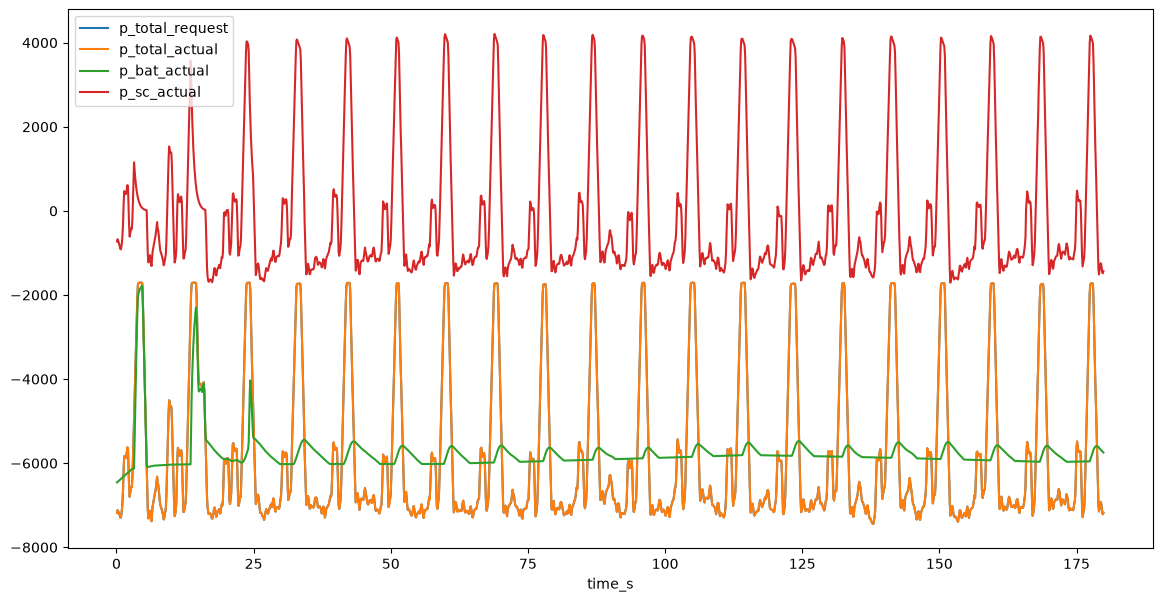

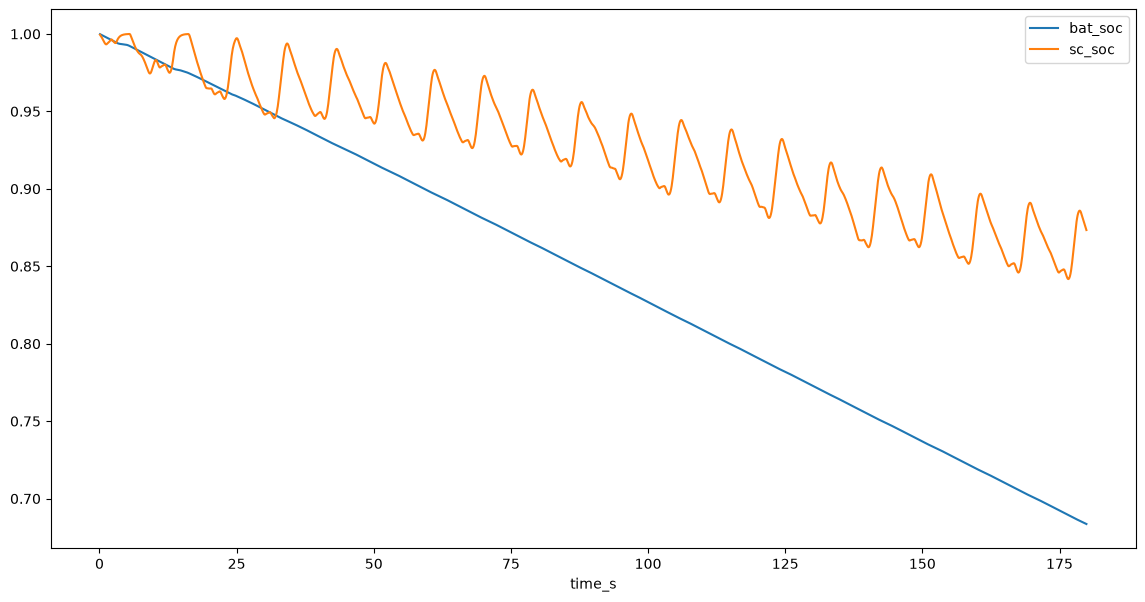

In [19]:
log = res_trials.loc[("worst_case", 21, 10), "log"]

display(log.head())

log.plot(
    x="time_s",
    y=["p_total_request", "p_total_actual", "p_bat_actual", "p_sc_actual"],
    figsize=(14, 7)
)

log.plot(
    x="time_s",
    y=["bat_soc", "sc_soc"],
    figsize=(14, 7)
)